<a href="https://colab.research.google.com/github/thisaraniNJ/Individual_Research_Project/blob/dev/03_1_explore_transition_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Data used

| File (made by the preprocessing script 02) | What it holds |
|---|---|
| `prepared/cases.csv` | one row per case: flight conditions, the transition location stored by the solver for each surface (from `transiLoc.dat`), the laminar separation point (from `bledge_info.dat`) and the screening flags |
| `prepared/transition_inputs/*.parquet` | the N-factor envelope of each surface (built from `nfactor_ts.dat`) |
| `prepared/surfaces/*.parquet` | the points of each surface: $x/c$, $y/c$, pressure coefficient $C_p$ and skin friction coefficient $C_f$ |

Section 6 also reads one raw `nfactor_ts.dat` file, to show the N factor of every wave frequency.

### Words used in all five notebooks

- **Case**: one simulation of one airfoil at one Mach number, Reynolds number and angle of attack (AoA).
- **Surface**: the upper or the lower side of the airfoil in one case. Every case has two surfaces.
- **x/c**: position along the chord (0 = leading edge, 1 = trailing edge).
- **Transition location** $x_{tr}$: where the boundary layer changes from laminar (smooth) to turbulent.
- **Stored transition location**: the transition location written by the solver (`transiLoc.dat`).
- **N factor**: how much a small disturbance wave in the boundary layer has grown; the wave is $e^N$ times its starting size.
- **Station**: a position along the surface where the N factor is known.
- **Envelope** $N_{TS}(x)$: at each station, the largest N factor over all wave frequencies.
- **Threshold** $N_{crit}$: the N factor at which transition is predicted (the $e^N$ method).
- **Laminar separation point** $x_{sep}$: where the laminar boundary layer separates from the surface.
- **Eligible surface**: a surface whose stored transition location lies on the chord, that has N-factor data, and whose N-factor file has no unreadable part. Only eligible surfaces are compared with the solver (Notebook 2).
- **Mach band**: one of the four Mach-number ranges used for reporting: 0.1–0.3, 0.3–0.5, 0.5–0.7 and 0.7–0.85.

In [ ]:
# ---- Setup: run this cell first ----
# 1. Connect Google Drive (Colab asks for permission the first time)
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
setup_path = "/content/drive/MyDrive/IRP Scripts/new_transition_notebooks"

# 2. The Drive folder that holds these notebooks and transition_utils.py
import sys
sys.path.append(setup_path)

# 3. Libraries
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import transition_utils as tu     # shared settings and functions, written once for all five notebooks

tu.set_plot_style()
print("results are saved in:", tu.RESULTS_DIR)

results are saved in: /content/drive/MyDrive/unifoil_project/results/transition_notebooks


## 1. The case table

Each row of `cases.csv` is one case. The table below shows the columns that this component uses.

In [ ]:
cases = tu.load_cases()
print(f"cases:    {len(cases):,}")
print(f"airfoils: {cases['airfoil'].nunique():,}")

# The columns of cases.csv that this component uses
columns_used = ["airfoil", "case", "Mach", "Re", "AoA_stated",
                "x_tr_solver_upper", "x_tr_solver_lower",
                "x_sep_upper", "x_sep_lower",
                "bad_frequency_upper", "bad_frequency_lower",
                "keep_rq1", "keep_rq2"]
cases[columns_used].head()

cases:    63,373
airfoils: 4,618


,airfoil,case,Mach,Re,AoA_stated,x_tr_solver_upper,x_tr_solver_lower,x_sep_upper,x_sep_lower,bad_frequency_upper,bad_frequency_lower,keep_rq1,keep_rq2
0,1,0,0.339795,2890000.0,2.724399,0.450489,0.380719,0.494694,0.447288,False,False,True,True
1,1,1,0.690023,1300000.0,0.755782,0.286318,0.240091,0.422095,0.381267,False,False,True,True
2,1,2,0.664469,5170000.0,1.786138,0.387008,0.345893,0.254899,0.172231,False,False,True,True
3,1,3,0.190151,1330000.0,2.520059,0.496031,0.445012,0.504612,0.447472,False,False,True,True
4,1,4,0.261451,1040000.0,5.818668,0.496166,0.453401,0.504817,0.456300,False,False,True,True


The component works on **surfaces**, so the case table is turned into a surface table with one row per surface (two rows per case). The column `x_tr_stored` is the stored transition location of that surface and `x_sep` is its laminar separation point.

In [ ]:
surf = tu.make_surface_table(cases)
print(f"surfaces: {len(surf):,}")
surf.head()

surfaces: 126,746


,airfoil,case,surface,Mach,Re,AoA,x_tr_stored,x_sep,bad_frequency,keep_rq1,keep_rq2
0,1,0,lower,0.339795,2890000.0,2.724399,0.380719,0.447288,False,True,True
1,1,0,upper,0.339795,2890000.0,2.724399,0.450489,0.494694,False,True,True
2,1,1,lower,0.690023,1300000.0,0.755782,0.240091,0.381267,False,True,True
3,1,1,upper,0.690023,1300000.0,0.755782,0.286318,0.422095,False,True,True
4,1,2,lower,0.664469,5170000.0,1.786138,0.345893,0.172231,False,True,True


## 2. Flight conditions

The Mach number, Reynolds number and angle of attack of the cases were sampled together with a Latin hypercube design (Kanchi et al., 2025; McKay, Beckman and Conover, 1979). The histograms show how the cases are spread over each condition.

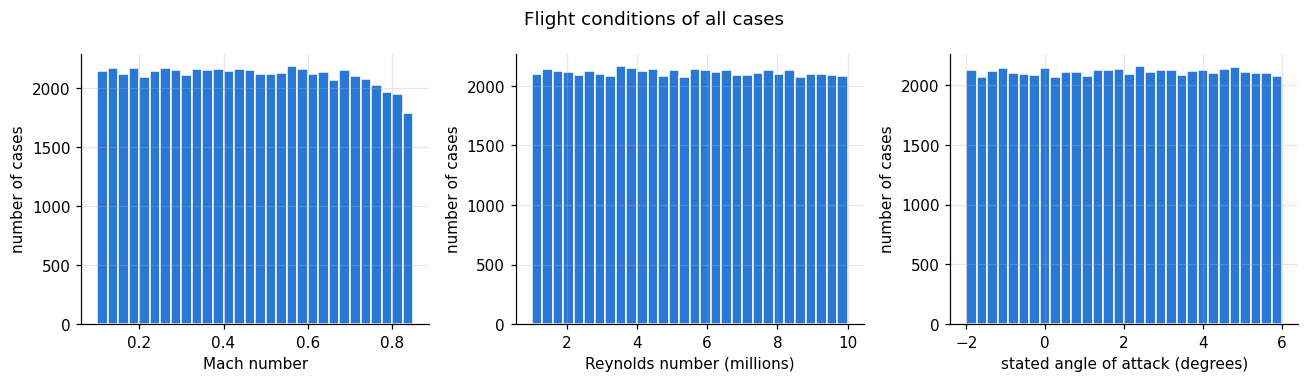

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))

axes[0].hist(cases["Mach"], bins=30, color=tu.COLOR_DATA, edgecolor="white")
axes[0].set_xlabel("Mach number")

axes[1].hist(cases["Re"] / 1e6, bins=30, color=tu.COLOR_DATA, edgecolor="white")
axes[1].set_xlabel("Reynolds number (millions)")

axes[2].hist(cases["AoA_stated"], bins=30, color=tu.COLOR_DATA, edgecolor="white")
axes[2].set_xlabel("stated angle of attack (degrees)")

for ax in axes:
    ax.set_ylabel("number of cases")
fig.suptitle("Flight conditions of all cases")
fig.tight_layout()
tu.save_figure(fig, "03_1_flight_conditions.png")
plt.show()

The bar chart shows how many cases were run for each airfoil.

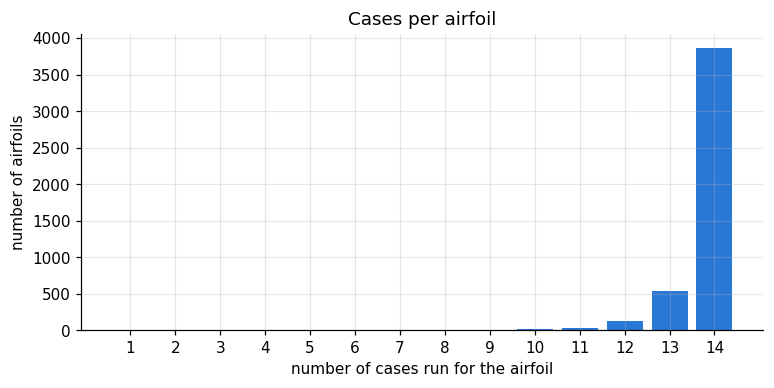

In [ ]:
cases_per_airfoil = cases.groupby("airfoil").size()                # number of cases of each airfoil
airfoils_by_count = cases_per_airfoil.value_counts().sort_index()   # number of airfoils with 1, 2, 3, ... cases

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(airfoils_by_count.index.astype(str), airfoils_by_count.values, color=tu.COLOR_DATA)
ax.set_xlabel("number of cases run for the airfoil")
ax.set_ylabel("number of airfoils")
ax.set_title("Cases per airfoil")
tu.save_figure(fig, "03_1_cases_per_airfoil.png")
plt.show()

## 3. Transition locations stored by the solver

The table counts, for each surface side, the stored values that lie on the chord (between 0 and 1), the values outside the chord, and the missing values. The second table lists the values found outside the chord.

In [ ]:
rows = []
for side in tu.SURFACES:
    values = surf.loc[surf["surface"] == side, "x_tr_stored"]
    on_chord = values.between(0, 1)
    rows.append({
        "surface": side,
        "on the chord (0 to 1)": on_chord.sum(),
        "outside the chord": (values.notna() & ~on_chord).sum(),
        "missing": values.isna().sum(),
    })
pd.DataFrame(rows).set_index("surface")

,on the chord (0 to 1),outside the chord,missing
surface,,,
upper,63090,283,0
lower,63090,283,0


In [ ]:
# Which values lie outside the chord, and on how many surfaces
outside = surf["x_tr_stored"].notna() & ~surf["x_tr_stored"].between(0, 1)
surf.loc[outside, "x_tr_stored"].value_counts().head(10).rename("surfaces").to_frame()

,surfaces
x_tr_stored,
7.000000,205
6.451703,1
6.297689,1
6.312830,1
6.205860,1
6.434185,1
6.360471,1
6.069308,1
6.663006,1


The histogram shows the stored values that lie on the chord, for the upper and the lower surfaces.

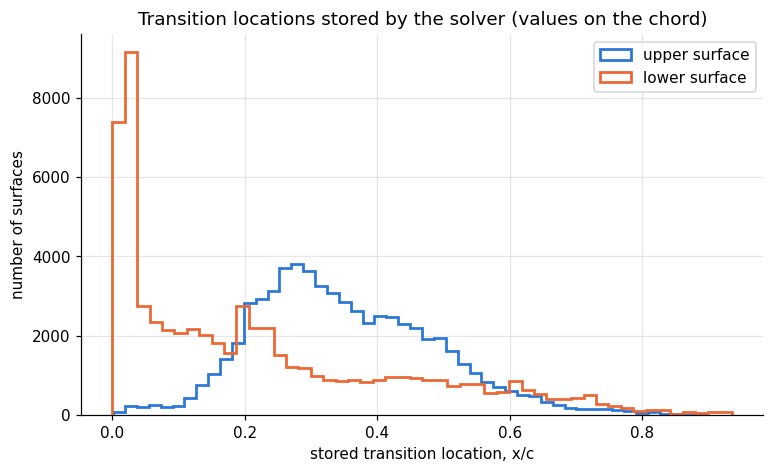

In [ ]:
fig, ax = plt.subplots()
for side in tu.SURFACES:
    on_chord = (surf["surface"] == side) & surf["x_tr_stored"].between(0, 1)
    ax.hist(surf.loc[on_chord, "x_tr_stored"], bins=50, histtype="step", linewidth=1.8,
            color=tu.SURFACE_COLORS[side], label=f"{side} surface")
ax.set_xlabel("stored transition location, x/c")
ax.set_ylabel("number of surfaces")
ax.set_title("Transition locations stored by the solver (values on the chord)")
ax.legend()
tu.save_figure(fig, "03_1_stored_transition_locations.png")
plt.show()

## 4. Laminar separation points

The laminar separation point is used when the envelope never reaches the threshold (Notebook 2). The left plot shows where it lies. The right plot compares it with the stored transition location: each point is one surface, and points on the black line have the same value for both.

upper surface: laminar separation point missing on 0 surfaces
lower surface: laminar separation point missing on 0 surfaces


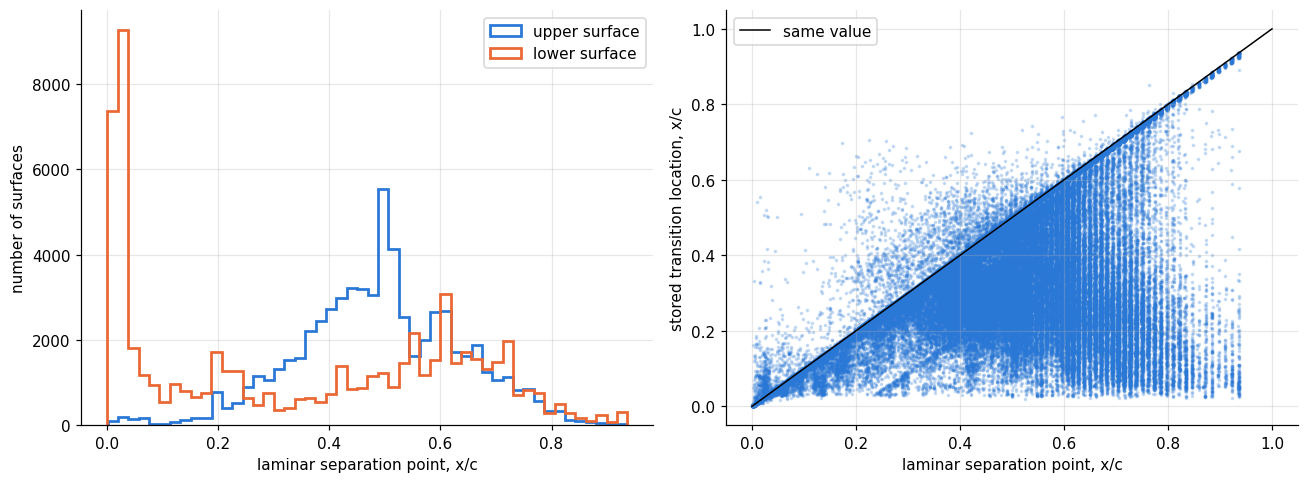

In [ ]:
for side in tu.SURFACES:
    missing = surf.loc[surf["surface"] == side, "x_sep"].isna().sum()
    print(f"{side} surface: laminar separation point missing on {missing:,} surfaces")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for side in tu.SURFACES:
    values = surf.loc[surf["surface"] == side, "x_sep"].dropna()
    axes[0].hist(values, bins=50, histtype="step", linewidth=1.8, color=tu.SURFACE_COLORS[side], label=f"{side} surface")
axes[0].set_xlabel("laminar separation point, x/c")
axes[0].set_ylabel("number of surfaces")
axes[0].legend()

both = surf[surf["x_tr_stored"].between(0, 1) & surf["x_sep"].notna()]
axes[1].scatter(both["x_sep"], both["x_tr_stored"], s=2, alpha=0.2, color=tu.COLOR_DATA)
axes[1].plot([0, 1], [0, 1], color="black", linewidth=1, label="same value")
axes[1].set_xlabel("laminar separation point, x/c")
axes[1].set_ylabel("stored transition location, x/c")
axes[1].legend()

fig.tight_layout()
tu.save_figure(fig, "03_1_laminar_separation.png")
plt.show()

## 5. N-factor data

The preprocessing script built the envelope of each surface from `nfactor_ts.dat`: at each station, the largest N factor over all wave frequencies (Shi et al., 2020; Kanchi et al., 2025). Some surfaces have no N-factor data, and on some surfaces a part of the file could not be read (it holds `****`).

In [ ]:
envelopes = tu.load_envelopes()
surf = tu.add_eligible_column(surf, envelopes)     # adds the columns has_N_data and eligible (eligible is used from Notebook 2)

rows = []
for side in tu.SURFACES:
    part = surf[surf["surface"] == side]
    rows.append({
        "surface": side,
        "with N-factor data": part["has_N_data"].sum(),
        "without N-factor data": (~part["has_N_data"]).sum(),
        "unreadable part ('****')": part["bad_frequency"].sum(),
    })
pd.DataFrame(rows).set_index("surface")

  envelope files read: 32 of 32
surfaces with an N-factor envelope: 95,630


,with N-factor data,without N-factor data,unreadable part ('****')
surface,,,
upper,57371,6002,10
lower,38259,25114,1


The left plot shows how many stations each envelope has. The right plot shows the largest N factor reached on each surface; the dashed line is the threshold stated in the UniFoil paper (Kanchi et al., 2025).

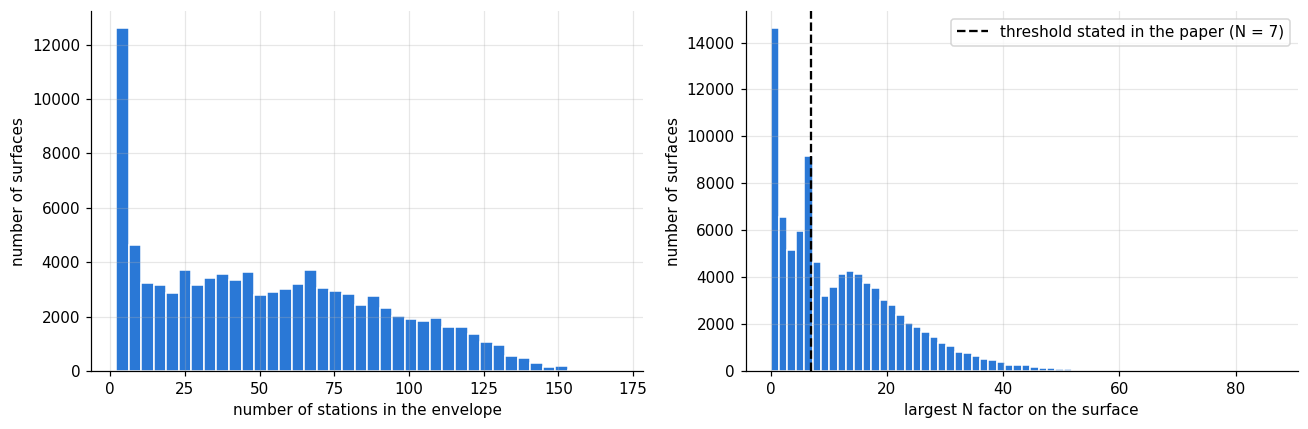

In [ ]:
stations = [len(x) for x, N in envelopes.values()]
largest_N = [N.max() for x, N in envelopes.values()]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(stations, bins=40, color=tu.COLOR_DATA, edgecolor="white")
axes[0].set_xlabel("number of stations in the envelope")
axes[0].set_ylabel("number of surfaces")

axes[1].hist(largest_N, bins=60, color=tu.COLOR_DATA, edgecolor="white")
axes[1].axvline(tu.STATED_NCRIT, color="black", linestyle="--",
                label=f"threshold stated in the paper (N = {tu.STATED_NCRIT:g})")
axes[1].set_xlabel("largest N factor on the surface")
axes[1].set_ylabel("number of surfaces")
axes[1].legend()

fig.tight_layout()
tu.save_figure(fig, "03_1_N_factor_data.png")
plt.show()

## 6. One surface in detail

One surface is chosen at random (with the fixed seed) from the surfaces that have N-factor data, a stored transition location on the chord, and a case kept by the RQ1 screening (so its surface points are good). To look at a particular surface instead, set `EXAMPLE`, for example `EXAMPLE = (12, 3, "upper")` for airfoil 12, case 3, upper surface.

In [ ]:
EXAMPLE = None    # (airfoil, case, "upper" or "lower"), or None for a random surface

if EXAMPLE is None:
    candidates = surf[surf["has_N_data"] & surf["x_tr_stored"].between(0, 1) & surf["keep_rq1"]]
    pick = candidates.sample(1, random_state=tu.SEED).iloc[0]
    EXAMPLE = (int(pick["airfoil"]), int(pick["case"]), pick["surface"])

airfoil, case, side = EXAMPLE
this_case = surf[(surf["airfoil"] == airfoil) & (surf["case"] == case)].set_index("surface")   # both surfaces of the case
example = this_case.loc[side]

print(f"airfoil {airfoil}, case {case}, {side} surface")
print(f"Mach {example['Mach']:.3f}, Reynolds number {example['Re']:.3g}, stated AoA {example['AoA']:.2f} degrees")
print(f"stored transition location: {example['x_tr_stored']:.4f}")
print(f"laminar separation point:   {example['x_sep']:.4f}")

airfoil 5640, case 9, upper surface
Mach 0.731, Reynolds number 3.06e+06, stated AoA 0.28 degrees
stored transition location: 0.5541
laminar separation point:   0.5541


### 6a. N factor of each wave frequency

`nfactor_ts.dat` holds one **zone** (block of rows) for each surface and wave frequency. In each zone, column 1 is $x/c$ and column 5 is the N factor. The envelope is the largest of these curves at each station. The functions below read the raw file from Drive in the same way as the preprocessing script; if the raw files are not on Drive, only the envelope is shown.

In [ ]:
import gzip
import csv
import zipfile
import re

# Raw file names look like "output_transi/airfoil_12_G1_A_L0_case_3/nfactor_ts.dat"
CASE_PATTERN = re.compile(r"airfoil_(\d+)_G\d+_[A-Za-z0-9]+_L\d+_case_(\d+)")


def read_raw_file(airfoil, case, file_name):
    """
    Text of one raw UniFoil file of one case (for example nfactor_ts.dat).
    The file is looked up in the list of downloaded files (manifest_files.csv.gz) and read from its shard zip.
    Returns None if the raw files are not on Drive.
    """
    manifest = os.path.join(tu.RAW_DIR, "manifest_files.csv.gz")
    if not os.path.exists(manifest):
        return None
    with gzip.open(manifest, "rt", newline="") as f:
        for row in csv.DictReader(f):                          # one row per downloaded file
            if not row["name"].endswith("/" + file_name):
                continue
            match = CASE_PATTERN.search(row["name"])
            if match is None or int(match.group(1)) != airfoil or int(match.group(2)) != case:
                continue
            folder = os.path.basename(row["archive"]).replace(".zip", "")
            shard = os.path.join(tu.RAW_DIR, "raw", folder, row["shard"])
            if not os.path.exists(shard):
                return None
            with zipfile.ZipFile(shard) as z:
                return z.read(row["name"]).decode("utf-8", "replace")
    return None


def to_numbers(line):
    """The numbers on one line (Fortran writes 1.0D-03 for 1.0E-03), or None if it is not a line of numbers."""
    try:
        return [float(p.replace("D", "E").replace("d", "e")) for p in line.replace(",", " ").split()]
    except ValueError:
        return None


def frequency_curves(text, side):
    """
    The N-factor curve of every wave frequency on one surface, read from nfactor_ts.dat.
    Skipped, as in the preprocessing script: the solver's own 'enveloped curve' zones,
    unreadable '****' zones and rows that are all zero.
    """
    curves = []
    current = None
    for line in text.splitlines():
        line = line.strip()
        if line.lower().startswith("zone"):                    # a new zone starts here
            header = line.lower()
            if side in header and "envelop" not in header and "*" not in header:
                current = {"x": [], "N": []}
                curves.append(current)
            else:
                current = None
            continue
        values = to_numbers(line)
        if current is not None and values is not None and len(values) >= 5 and any(values):
            current["x"].append(values[0])                     # column 1: x/c
            current["N"].append(values[4])                     # column 5: N factor
    return curves

wave frequencies on this surface: 20


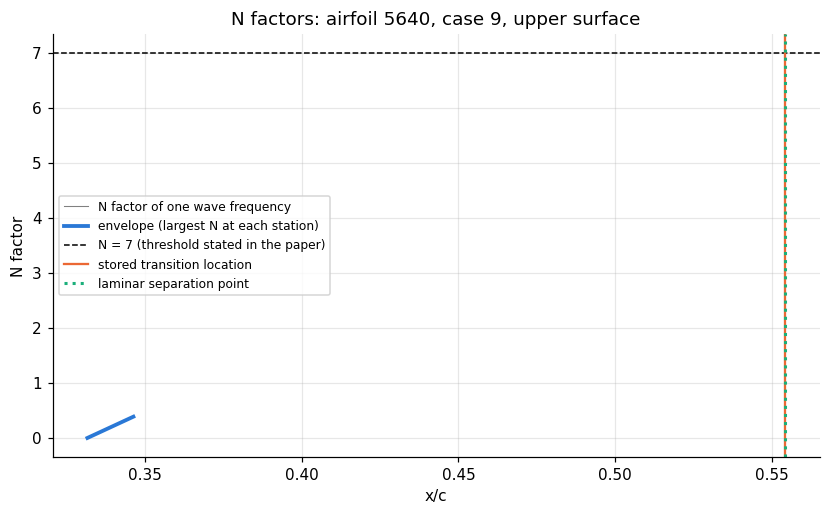

In [ ]:
text = read_raw_file(airfoil, case, "nfactor_ts.dat")
x_env, N_env = envelopes[(airfoil, case, side)]

fig, ax = plt.subplots(figsize=(9, 5))
if text is None:
    print("Raw files not found on Drive: only the envelope is shown.")
else:
    curves = frequency_curves(text, side)
    print(f"wave frequencies on this surface: {len(curves)}")
    for curve in curves:
        c = pd.DataFrame(curve).sort_values("x")
        ax.plot(c["x"], c["N"], color="grey", linewidth=0.7, alpha=0.6)
    ax.plot([], [], color="grey", linewidth=0.7, label="N factor of one wave frequency")   # legend entry only

ax.plot(x_env, N_env, color=tu.COLOR_DATA, linewidth=2.5, label="envelope (largest N at each station)")
ax.axhline(tu.STATED_NCRIT, color="black", linestyle="--", linewidth=1,
           label=f"N = {tu.STATED_NCRIT:g} (threshold stated in the paper)")
ax.axvline(example["x_tr_stored"], color=tu.COLOR_STORED, linewidth=1.5, label="stored transition location")
if np.isfinite(example["x_sep"]):
    ax.axvline(example["x_sep"], color=tu.COLOR_SEPARATION, linestyle=":", linewidth=2, label="laminar separation point")
ax.set_xlabel("x/c")
ax.set_ylabel("N factor")
ax.set_title(f"N factors: airfoil {airfoil}, case {case}, {side} surface")
ax.legend(fontsize=8)
tu.save_figure(fig, "03_1_example_N_factors.png")
plt.show()

### 6b. Skin friction along the same surface

The skin friction coefficient $C_f$ along the surface, from the prepared surface files, with the stored transition location and the laminar separation point marked. Notebook 5 uses this quantity.

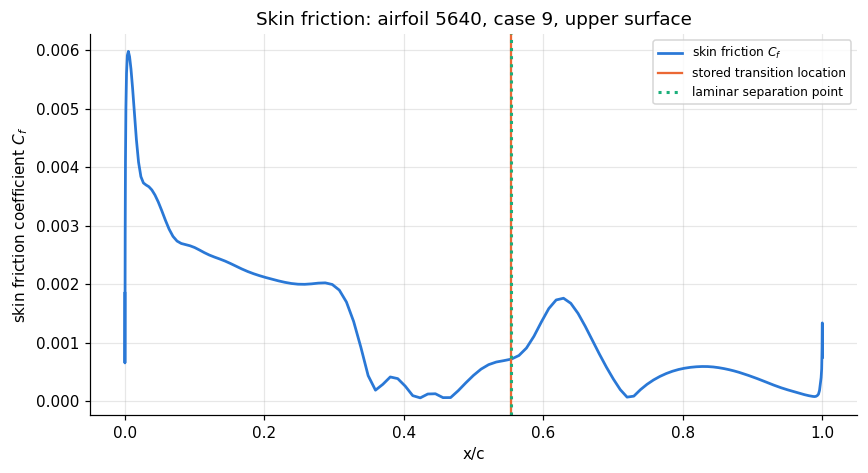

In [ ]:
points = tu.read_surface_points(airfoil, case)        # both surfaces of the case
this_side = points[points["surface"] == side]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(this_side["x"], this_side["cf"], color=tu.COLOR_DATA, linewidth=1.8, label="skin friction $C_f$")
ax.axvline(example["x_tr_stored"], color=tu.COLOR_STORED, linewidth=1.5, label="stored transition location")
if np.isfinite(example["x_sep"]):
    ax.axvline(example["x_sep"], color=tu.COLOR_SEPARATION, linestyle=":", linewidth=2, label="laminar separation point")
ax.set_xlabel("x/c")
ax.set_ylabel("skin friction coefficient $C_f$")
ax.set_title(f"Skin friction: airfoil {airfoil}, case {case}, {side} surface")
ax.legend(fontsize=8)
tu.save_figure(fig, "03_1_example_skin_friction.png")
plt.show()

### 6c. The airfoil shape

Both surfaces of the same case, with the stored transition location of each surface marked.

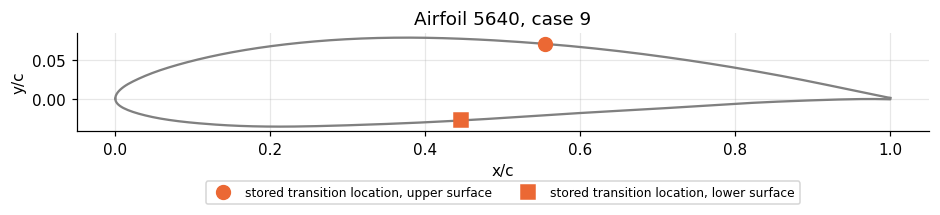

In [ ]:
markers = {"upper": "o", "lower": "s"}          # a different marker shape for each surface

fig, ax = plt.subplots(figsize=(10, 3.2))
for s in tu.SURFACES:
    pts = points[points["surface"] == s]
    ax.plot(pts["x"], pts["y"], color="grey", linewidth=1.5)
    x_tr = this_case.loc[s, "x_tr_stored"]
    if 0 <= x_tr <= 1:
        y_tr = np.interp(x_tr, pts["x"], pts["y"])     # height of the surface at x_tr
        ax.plot(x_tr, y_tr, markers[s], color=tu.COLOR_STORED, markersize=9,
                label=f"stored transition location, {s} surface")
ax.set_aspect("equal")
ax.set_xlabel("x/c")
ax.set_ylabel("y/c")
ax.set_title(f"Airfoil {airfoil}, case {case}")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.45), ncol=2)    # legend below the plot
tu.save_figure(fig, "03_1_example_shape.png")
plt.show()

## 7. More examples

Six more surfaces chosen at random (another fixed seed), each with its envelope, the stored transition location and the laminar separation point. The dashed line is the threshold stated in the UniFoil paper.

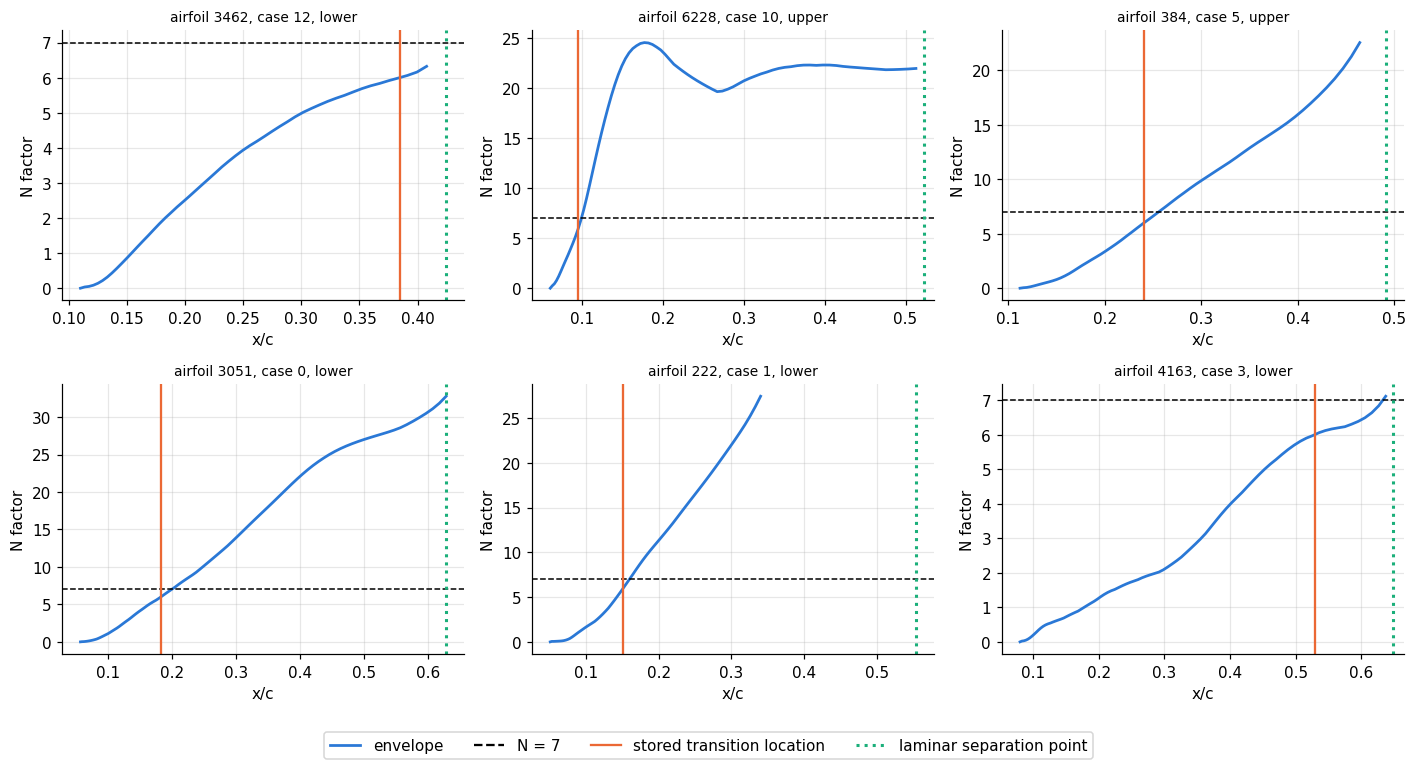

In [ ]:
candidates = surf[surf["has_N_data"] & surf["x_tr_stored"].between(0, 1)]
picks = candidates.sample(min(6, len(candidates)), random_state=tu.SEED + 1)   # another seed, so other surfaces

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, row in zip(axes.ravel(), picks.itertuples(index=False)):
    x, N = envelopes[(row.airfoil, row.case, row.surface)]
    ax.plot(x, N, color=tu.COLOR_DATA, linewidth=1.8)
    ax.axhline(tu.STATED_NCRIT, color="black", linestyle="--", linewidth=1)
    ax.axvline(row.x_tr_stored, color=tu.COLOR_STORED, linewidth=1.5)
    if np.isfinite(row.x_sep):
        ax.axvline(row.x_sep, color=tu.COLOR_SEPARATION, linestyle=":", linewidth=2)
    ax.set_title(f"airfoil {row.airfoil}, case {row.case}, {row.surface}", fontsize=9)
    ax.set_xlabel("x/c")
    ax.set_ylabel("N factor")
for ax in axes.ravel()[len(picks):]:          # hide panels that are not used
    ax.axis("off")

# One legend for all panels
legend_lines = [plt.Line2D([], [], color=tu.COLOR_DATA, linewidth=1.8, label="envelope"),
                plt.Line2D([], [], color="black", linestyle="--", label=f"N = {tu.STATED_NCRIT:g}"),
                plt.Line2D([], [], color=tu.COLOR_STORED, label="stored transition location"),
                plt.Line2D([], [], color=tu.COLOR_SEPARATION, linestyle=":", linewidth=2, label="laminar separation point")]
fig.legend(handles=legend_lines, loc="lower center", ncol=4)
fig.tight_layout(rect=[0, 0.06, 1, 1])
tu.save_figure(fig, "03_1_more_examples.png")
plt.show()

## Files saved by this notebook

In `results/transition_notebooks`: `03_1_flight_conditions.png`, `03_1_cases_per_airfoil.png`, `03_1_stored_transition_locations.png`, `03_1_laminar_separation.png`, `03_1_N_factor_data.png`, `03_1_example_N_factors.png`, `03_1_example_skin_friction.png`, `03_1_example_shape.png`, `03_1_more_examples.png`.

**Next:** Notebook 2 calculates the transition locations with the $e^N$ rule.